# Plot a random source spectrum from saved UVEX inputs

Reads the FITS file written by `save_inputs` (point-source table + spectra) from `approx_spectra.py`, picks a random source,
looks up its observed photometry in `table_field` via `source_id`, and plots the model spectrum with
model and observed band-averaged fluxes.

Requirements:
- `approx_spectra.py` importable (same folder as this notebook, or on `sys.path`)
- the saved inputs FITS file and the matched GALEX + Gaia catalog
- `load_bandpass` and `SourceSpectrum.from_vega()` still query SVO / STScI, as in `approx_spectra.py`

# Preamble

In [ ]:
%matplotlib inline
%config InlineBackend.figure_format='retina'

import os
import re
import sys
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from astropy.table import Table
from synphot import Observation, SourceSpectrum, units

sys.path.append(os.path.join(os.path.expanduser('~/Desktop'), 'github'))
from my_style import setup, clear_plt, get_dir
_info = setup()
dir_uvgaps = get_dir('uvex-sim', 'uvgaps-data')

sys.path.append(os.path.join(os.path.expanduser('~/Desktop'), 'github/USIM-FEST2'))
from approx_spectra import (BANDS, load_bandpass, synthetic_mags,
                            mag_err, load_inputs)

In [2]:
file_inputs = os.path.join(dir_uvgaps, 'UVEXfov4996_gaia_galex_ps_inputs_2026_10_12.fits')
file_catalog = os.path.join(dir_uvgaps, 'uvex_fovs_plane_gaia_ps2_2026_10_11.fits')
field_id = 4996
nuv_floor = 0.1
gaia_floor = 0.03
seed = None

In [3]:
def value_as_float(row, name):
    value = row[name]
    return np.nan if np.ma.is_masked(value) else float(value)

## Load the saved inputs

In [4]:
point_sources, spectra = load_inputs(file_inputs)
print(point_sources.colnames, '| masked:', point_sources.masked)       # UVEXInput expect ['ra', 'dec', 'ref', 'scale'], False
print(f'{len(point_sources):,} sources, {len(spectra):,} distinct spectra')
print('metadata keys:', list(point_sources.meta.keys()))

['ra', 'dec', 'ref', 'scale'] | masked: False
16,288 sources, 346 distinct spectra
metadata keys: ['source_id']


## Load the catalog for this field

In [5]:
table_plane = Table.read(file_catalog)
table_field = table_plane[table_plane['field_id'] == field_id]
print(f'{len(table_field):,} catalog rows in field {field_id}')

16,288 catalog rows in field 4996


## Bandpasses and Vega
Pull filter curves for each survey from SVO

In [6]:
vega = SourceSpectrum.from_vega() # NOTE: only for Gaia zero points
bandpasses = {name: load_bandpass(svo_id)
              for name, (svo_id, _) in BANDS.items()}
# pivot wavelengths
pivots = np.array([bandpasses[name].pivot().to_value(u.AA)
                   for name in BANDS])

  points: [10987.5 10990. ]
  lookup_table: [-2.97498e-05 -1.87648e-04] [synphot.models]


## Pick a random source and find it in the catalog

In [19]:
rng = np.random.default_rng()
k = rng.integers(len(point_sources))
ref = str(point_sources['ref'][k])
scale = float(point_sources['scale'][k])
source_id = point_sources.meta['source_id'][k]

match = np.flatnonzero(np.asarray(table_field['source_id']) == source_id)
if len(match) != 1:
    raise ValueError(f'source_id {source_id} matched {len(match)} catalog rows')
row = table_field[match[0]]
print(f'row {k}: source_id {source_id}, ref {ref}, scale {scale:.3e}')
ra, dec = row['ra_gaia'], row['dec_gaia']

row 14884: source_id 5615507119189305472, ref BB_T6630_E0.050, scale 9.809e+00


## Observed magnitudes and errors

In [21]:
gaia_bandpass = ['g', 'bp', 'rp']
gaia_magcols = [f'phot_{b}_mean_mag' for b in gaia_bandpass]
panstarrs_bandpass = ['g', 'r', 'i', 'z', 'y']
panstarrs_magcols = [f'{b}MeanPSFMag' for b in panstarrs_bandpass]
mag_cols = ['nuv'] + gaia_magcols + panstarrs_magcols

obs_mags = np.array([value_as_float(row, c) for c in mag_cols])

nuv_snr = value_as_float(row, 'FLUX_AUTO') / value_as_float(row, 'FLUXERR_AUTO')
gaia_snr = [value_as_float(row, f'phot_{b}_mean_flux') / value_as_float(row, f'phot_{b}_mean_flux_error')
            for b in gaia_bandpass]
ps_err = [0.05 for _ in panstarrs_bandpass]

obs_errs = np.array([mag_err(nuv_snr, nuv_floor)]
                    + [mag_err(s, gaia_floor) for s in gaia_snr]
                    + ps_err)
print(dict(zip(BANDS, np.round(obs_mags, 3))))

{'NUV': np.float64(15.316), 'G': np.float64(11.649), 'BP': np.float64(11.875), 'RP': np.float64(11.288), 'ps_g': np.float64(12.031), 'ps_r': np.float64(11.845), 'ps_i': np.float64(11.777), 'ps_z': np.float64(11.718), 'ps_y': np.float64(11.682)}


## Model spectrum and photometry

In [22]:
model_sp = spectra[ref] * scale
wave = model_sp.waveset
flux = model_sp(wave, flux_unit=units.FLAM)

synth_mags = synthetic_mags(model_sp, bandpasses, vega)
synth_flam = np.array([Observation(model_sp, bandpasses[name])
                       .effstim(flux_unit=units.FLAM).value
                       for name in BANDS])
obs_flam = synth_flam * 10**(-0.4 * (obs_mags - synth_mags))
obs_flam_err = obs_flam * obs_errs * np.log(10) / 2.5

resid_sigma = (synth_mags - obs_mags) / obs_errs
resid_frac = obs_flam / synth_flam - 1
for name, s, f in zip(BANDS, resid_sigma, resid_frac):
    print(f'{name:>3}: {s:+.2f} sigma, {100 * f:+.1f}% in flux')

mag_ab = model_sp(wave, flux_unit=u.ABmag).value
synth_ab = np.array([Observation(model_sp, bandpasses[name])
                     .effstim(flux_unit=u.ABmag).value
                     for name in BANDS])
obs_ab = obs_mags + (synth_ab - synth_mags)

# Checking magnitude offset for VEGA-AB
vega_ab = np.array([Observation(vega, bandpasses[name])
                    .effstim(flux_unit=u.ABmag).value
                    if system == 'Vega' else 0.0
                    for name, (_, system) in BANDS.items()])
print(np.round(synth_ab - synth_mags, 4))
print(np.round(vega_ab, 4))

NUV: -1.78 sigma, -15.3% in flux
  G: +0.43 sigma, +1.2% in flux
 BP: +3.85 sigma, +11.2% in flux
 RP: +0.05 sigma, +0.1% in flux
ps_g: +1.25 sigma, +5.9% in flux
ps_r: -1.66 sigma, -7.3% in flux
ps_i: -2.42 sigma, -10.6% in flux
ps_z: -1.42 sigma, -6.3% in flux
ps_y: -0.46 sigma, -2.1% in flux
[0.     0.1664 0.0479 0.3828 0.     0.     0.     0.     0.    ]
[0.     0.1664 0.0479 0.3828 0.     0.     0.     0.     0.    ]


## Recover Teff and E(B-V) from the spectrum key
Only works if keys have the form `BB_Txxxx_Ey.yyy` and the grids below match the ones used in the fit; otherwise the plot is labelled with the key.

In [29]:
# teff_grid = np.geomspace(3000.0, 40000.0, 50)
# ebv_grid = np.arange(0.0, 3.01, 0.05)

key_match = re.fullmatch(r'BB_T(\d+)_E(\d+\.\d+)', ref)
if key_match:
    teff_src = float(key_match.group(1))
    ebv_src = float(key_match.group(2))
    fit_label = [f'Fit: $T_{{\\rm eff}}$ = {teff_src:.0f} K,\n'
                 f'       E(B-V) = {ebv_src:.2f}']
else:
    fit_label = f'Fit: {ref}'
print(fit_label)

['Fit: $T_{\\rm eff}$ = 6630 K,\n       E(B-V) = 0.05']


## Plot

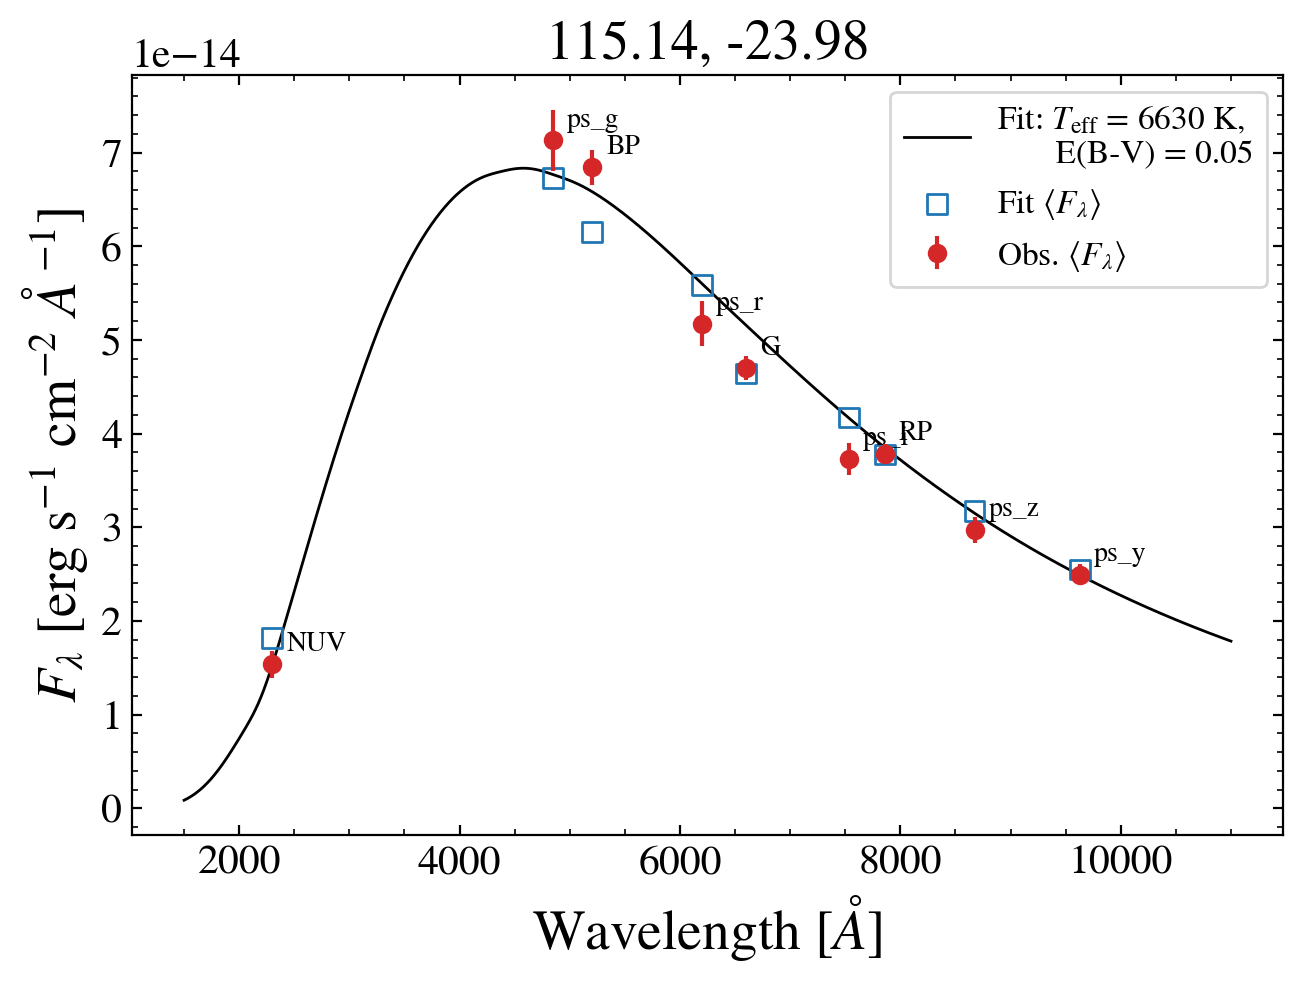

In [38]:
in_range = (wave >= 1500 * u.AA) & (wave <= 11000 * u.AA)

fig = plt.figure(layout='constrained')
ax = fig.add_subplot()
ax.plot(wave[in_range].to_value(u.AA), flux[in_range].value,
        color='k', lw=1, label=fit_label)
ax.scatter(pivots, synth_flam, marker='s', s=50, facecolors='none',
           edgecolors='C0', zorder=3, label=f'Fit $\\left\\langle F_{{\\lambda}}\\right\\rangle$')
ax.errorbar(pivots, obs_flam, yerr=obs_flam_err, fmt='o', color='C3',
            zorder=4, label=f'Obs. $\\left\\langle F_{{\\lambda}}\\right\\rangle$')
for name, x, y in zip(BANDS, pivots, obs_flam):
    ax.annotate(name, (x, y), textcoords='offset points', xytext=(5, 5))

ax.set_title(f'{ra:.2f}, {dec:.2f}')
ax.set_xlabel(f'Wavelength [$\\AA$]')
ax.set_ylabel(f'$F_{{\\lambda}}$ [erg s$^{{-1}}$ cm$^{{-2}}$ $\\AA^{{-1}}$]')
ax.legend(fontsize=12)
plt.show()
clear_plt()